# Day 4: NumPy, Pandas, Matplotlib & Seaborn
### The Essential Data Science Stack for Machine Learning

**Topics covered:**
1. 🔢 NumPy — Arrays & Vectorized Operations
2. 🐼 Pandas — DataFrames & Data Cleaning
3. 📊 Matplotlib — Core Plotting
4. 🌊 Seaborn — Statistical Visualizations
5. 🔗 Putting It All Together — ML Dataset EDA

> **Dataset used:** Student Performance Dataset (generated to reflect real-world patterns)  



## ⚙️ Setup — Import Libraries & Generate Dataset

In [1]:
linespace = "="*60

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
import warnings

warnings.filterwarnings("ignore")

# Plot styling
sns.set_theme(style="darkgrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 100

print("✅ All libraries imported successfully!")
print(f"NumPy  version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

✅ All libraries imported successfully!
NumPy  version: 2.1.3
Pandas version: 2.2.3


In [3]:
# ── Generate a realistic Student Performance Dataset ──
np.random.seed(42)
n = 200

study_hours   = np.round(np.random.uniform(1, 10, n), 1)
attendance    = np.round(np.random.uniform(50, 100, n), 1)
prev_score    = np.round(np.random.uniform(40, 95, n), 1)
sleep_hours   = np.round(np.random.uniform(4, 9, n), 1)
tutoring      = np.random.choice(["Yes", "No"], n, p=[0.4, 0.6])

# Final score influenced by all features
noise = np.random.normal(0, 5, n)
final_score = (
    0.4 * study_hours * 7 +
    0.2 * (attendance - 50) * 0.8 +
    0.3 * prev_score +
    0.1 * sleep_hours * 3 +
    np.where(tutoring == "Yes", 5, 0) +
    noise
)
final_score = np.clip(np.round(final_score, 1), 0, 100)

# Introduce some missing values (real-world messiness)
for col_idx in np.random.choice(n, 10, replace=False):
    study_hours[col_idx] = np.nan
for col_idx in np.random.choice(n, 8, replace=False):
    sleep_hours[col_idx] = np.nan

df = pd.DataFrame({
    "study_hours":   study_hours,
    "attendance":    attendance,
    "prev_score":    prev_score,
    "sleep_hours":   sleep_hours,
    "tutoring":      tutoring,
    "final_score":   final_score
})

# Save as CSV so students can load it like a real dataset
df.to_csv("student_performance.csv", index=False)
print(f"✅ Dataset created: {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

✅ Dataset created: 200 rows × 6 columns


,study_hours,attendance,prev_score,sleep_hours,tutoring,final_score
0,4.4,82.1,45.7,4.8,No,33.5
1,9.6,54.2,89.6,5.4,Yes,54.4
2,7.6,58.1,67.8,4.9,No,46.3
3,6.4,94.9,85.5,4.4,No,55.1
4,2.4,80.3,57.6,4.6,No,33.0


---
## 1. 🔢 NumPy — Fast Numerical Computing

NumPy is the backbone of ML in Python. It provides **N-dimensional arrays** and **vectorized math** that replace slow Python loops.


### 1.1 Creating Arrays

In [ ]:
# 1D array
a = np.array([1, 2, 3, 4, 5])
print("1D:", a)

# 2D array (matrix)
b = np.array([[1, 2, 3],
              [4, 5, 6]])
print("2D:\n", b)
print("Shape:", b.shape)
print("Dtype:", b.dtype)

1D: [1 2 3 4 5]
2D:
 [[1 2 3]
 [4 5 6]]
Shape: (2, 3)
Dtype: int64


In [ ]:
# Array creation shortcuts
print(np.zeros((3, 3)))         # all zeros
print(linespace)
print(np.ones((2, 4)))          # all ones
print(linespace)
print(np.eye(3))                # identity matrix
print(linespace)
print(np.arange(0, 10, 2))     # like range()
print(linespace)
print(np.linspace(0, 1, 10))    # evenly spaced

[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
[[1. 1. 1. 1.]
 [1. 1. 1. 1.]]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[0 2 4 6 8]
[0.         0.11111111 0.22222222 0.33333333 0.44444444 0.55555556
 0.66666667 0.77777778 0.88888889 1.        ]


### 1.2 Indexing & Slicing

In [ ]:
arr = np.array([10, 20, 30, 40, 50, 60])
print(arr[0])       # first element
print(arr[-1])      # last element
print(arr[1:4])     # slice
print(arr[::2])     # every other element

matrix = np.arange(1, 10).reshape(3, 3)
print("\nMatrix:\n", matrix)
print("Row 0:", matrix[0])
print("Col 1:", matrix[:, 1])
print("Sub-matrix:\n", matrix[:2, :2])

10
60
[20 30 40]
[10 30 50]

Matrix:
 [[1 2 3]
 [4 5 6]
 [7 8 9]]
Row 0: [1 2 3]
Col 1: [2 5 8]
Sub-matrix:
 [[1 2]
 [4 5]]


### 1.3 Vectorized Operations (No Loops Needed!)

In [ ]:
s = [20, 20, 30]

In [ ]:
scores = np.array([55, 70, 85, 90, 45, 60])

# Operations apply element-wise — no for loop needed
print("Normalized:", (scores - scores.min()) / (scores.max() - scores.min()))
print("Scaled ×2: ", scores * 2)
print("Above 60:  ", scores[scores > 60])   # boolean masking

Normalized: [0.22222222 0.55555556 0.88888889 1.         0.         0.33333333]
Scaled ×2:  [110 140 170 180  90 120]
Above 60:   [70 85 90]


### 1.4 Statistical Functions

In [ ]:
data = np.array([72, 85, 60, 91, 78, 55, 88, 76])

print(f"Mean:    {np.mean(data):.2f}")
print(f"Median:  {np.median(data):.2f}")
print(f"Std Dev: {np.std(data):.2f}")
print(f"Variance:{np.var(data):.2f}")
print(f"Min/Max: {np.min(data)} / {np.max(data)}")
print(f"Sum:     {np.sum(data)}")

Mean:    75.62
Median:  77.00
Std Dev: 12.07
Variance:145.73
Min/Max: 55 / 91
Sum:     605


In [ ]:
# Handling NaN (missing values) — critical in ML!
arr_with_nan = np.array([10, np.nan, 30, np.nan, 50])
print("With NaN:    ", arr_with_nan)
print("NaN-safe mean:", np.nanmean(arr_with_nan))
print("NaN-safe std: ", np.nanstd(arr_with_nan))

### 1.5 Array Reshaping & Stacking

In [ ]:
a = np.arange(12)
print("Original:", a)
print("Reshaped (3×4):\n", a.reshape(3, 4))
print("Flattened:", a.reshape(3, 4).flatten())

# Stacking arrays — useful for combining feature arrays
X1 = np.array([[1, 2], [3, 4]])
X2 = np.array([[5, 6], [7, 8]])
print("Vertical stack:\n", np.vstack([X1, X2]))
print("Horizontal stack:\n", np.hstack([X1, X2]))

Original: [ 0  1  2  3  4  5  6  7  8  9 10 11]
Reshaped (3×4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
Flattened: [ 0  1  2  3  4  5  6  7  8  9 10 11]
Vertical stack:
 [[1 2]
 [3 4]
 [5 6]
 [7 8]]
Horizontal stack:
 [[1 2 5 6]
 [3 4 7 8]]


---
## 2. 🐼 Pandas — Data Manipulation & Cleaning

Pandas provides the **DataFrame** — a 2D labeled table like an Excel sheet — that every ML project uses to load, clean, and prepare data.


### 2.1 Loading & Inspecting Data

In [4]:
df = pd.read_csv("student_performance.csv")

print("Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Shape: (200, 6)

First 5 rows:


,study_hours,attendance,prev_score,sleep_hours,tutoring,final_score
0,4.4,82.1,45.7,4.8,No,33.5
1,9.6,54.2,89.6,5.4,Yes,54.4
2,7.6,58.1,67.8,4.9,No,46.3
3,6.4,94.9,85.5,4.4,No,55.1
4,2.4,80.3,57.6,4.6,No,33.0


In [5]:
# Quick data overview
print("Info:")
df.info()

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   study_hours  190 non-null    float64
 1   attendance   200 non-null    float64
 2   prev_score   200 non-null    float64
 3   sleep_hours  192 non-null    float64
 4   tutoring     200 non-null    object 
 5   final_score  200 non-null    float64
dtypes: float64(5), object(1)
memory usage: 9.5+ KB


In [6]:
print("Statistical Summary:")
df.describe().T

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
study_hours,190.0,5.338947,2.655803,1.0,3.10,5.30,7.800,9.9
attendance,200.0,75.219000,14.647820,50.3,63.10,77.05,87.075,99.5
prev_score,200.0,68.637500,16.898477,40.6,54.05,68.90,84.625,95.0
sleep_hours,192.0,6.406250,1.399874,4.1,5.20,6.40,7.700,8.9
final_score,200.0,44.434500,10.166902,20.0,37.85,45.10,50.125,73.6


### 2.2 Handling Missing Values

In [ ]:
df.isnull().sum()

,0
study_hours,10
attendance,0
prev_score,0
sleep_hours,8
tutoring,0
final_score,0


In [ ]:
print("Missing values per column:")
print(df.isnull().sum().sort_values(ascending=False))
print(f"\nTotal missing: {df.isnull().sum().sum()}")

Missing values per column:
study_hours    10
sleep_hours     8
attendance      0
prev_score      0
tutoring        0
final_score     0
dtype: int64

Total missing: 18


In [7]:
# Filling missing values with median (robust to outliers)
df["study_hours"].fillna(df["study_hours"].median(), inplace=True)
df["sleep_hours"].fillna(df["sleep_hours"].median(), inplace=True)

print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
study_hours    0
attendance     0
prev_score     0
sleep_hours    0
tutoring       0
final_score    0
dtype: int64


### 2.3 Selecting, Filtering & Sorting

In [10]:
# Select a single column
print(df["final_score"].tail())

# Select multiple columns
print(df[["study_hours", "final_score"]].head())

# Filter rows
high_scorers = df[df["final_score"] >= 60]
print(f"\nStudents with final_score ≥ 60: {len(high_scorers)}")
high_scorers.head()

195    36.8
196    51.2
197    38.7
198    40.7
199    47.5
Name: final_score, dtype: float64
   study_hours  final_score
0          4.4         33.5
1          9.6         54.4
2          7.6         46.3
3          6.4         55.1
4          2.4         33.0

Students with final_score ≥ 60: 14


,study_hours,attendance,prev_score,sleep_hours,tutoring,final_score
11,9.7,84.6,92.3,8.0,No,63.8
12,8.5,82.6,92.3,7.1,Yes,65.2
41,5.5,97.7,94.3,5.6,No,60.0
45,7.0,96.4,92.1,8.5,No,64.5
67,8.2,85.1,87.8,4.8,Yes,73.6


In [11]:
# Filtering with multiple conditions
top_students = df[(df["study_hours"] >= 7) & (df["attendance"] >= 85)]
print(f"High study + high attendance: {len(top_students)} students")

# Sorting
df.sort_values("final_score", ascending=False).head()

High study + high attendance: 19 students


,study_hours,attendance,prev_score,sleep_hours,tutoring,final_score
67,8.2,85.1,87.8,4.8,Yes,73.6
140,9.7,74.6,92.5,6.3,Yes,71.1
88,9.0,64.3,92.3,7.8,Yes,65.8
12,8.5,82.6,92.3,7.1,Yes,65.2
73,8.3,95.7,89.0,6.6,No,65.2


### 2.4 Creating New Features (Feature Engineering)

In [ ]:
df.iloc[ 0:10:, 0:2]

In [12]:
# New column: study efficiency index
df["study_efficiency"] = df["study_hours"] * (df["attendance"] / 100)

# Encode categorical column
df["tutoring_encoded"] = (df["tutoring"] == "Yes").astype(int)

# Binning scores into grade categories
df["grade"] = pd.cut(df["final_score"],
                     bins=[0, 40, 55, 70, 85, 100],
                     labels=["F", "D", "C", "B", "A"])

print(df[["study_hours", "study_efficiency", "tutoring_encoded", "grade"]].head(8))

   study_hours  study_efficiency  tutoring_encoded grade
0          4.4            3.6124                 0     F
1          9.6            5.2032                 1     D
2          7.6            4.4156                 0     D
3          6.4            6.0736                 0     C
4          2.4            1.9272                 0     F
5          2.4            1.2120                 0     D
6          1.5            0.8265                 0     F
7          8.8            7.3216                 0     D


### 2.5 GroupBy & Aggregation

In [13]:
# Average final score by tutoring status
print("Avg score by tutoring:")
print(df.groupby("tutoring")["final_score"].mean().round(2))

print("\nGrade distribution:")
print(df["grade"].value_counts().sort_index())

# Multiple aggregations
summary = df.groupby("grade").agg(
    count=("final_score", "count"),
    avg_study=("study_hours", "mean"),
    avg_attendance=("attendance", "mean")
).round(2)
print("\nSummary by Grade:")
print(summary)

Avg score by tutoring:
tutoring
No     42.14
Yes    47.35
Name: final_score, dtype: float64

Grade distribution:
grade
F     67
D    105
C     26
B      2
A      0
Name: count, dtype: int64

Summary by Grade:
       count  avg_study  avg_attendance
grade                                  
F         67       3.65           71.93
D        105       5.68           76.42
C         26       8.02           78.52
B          2       8.95           79.85
A          0        NaN             NaN


---
## 3. 📊 Matplotlib — Core Plotting

Matplotlib gives full control over every chart element. It's the foundation all other Python viz libraries build on.


### 3.1 Line Plot

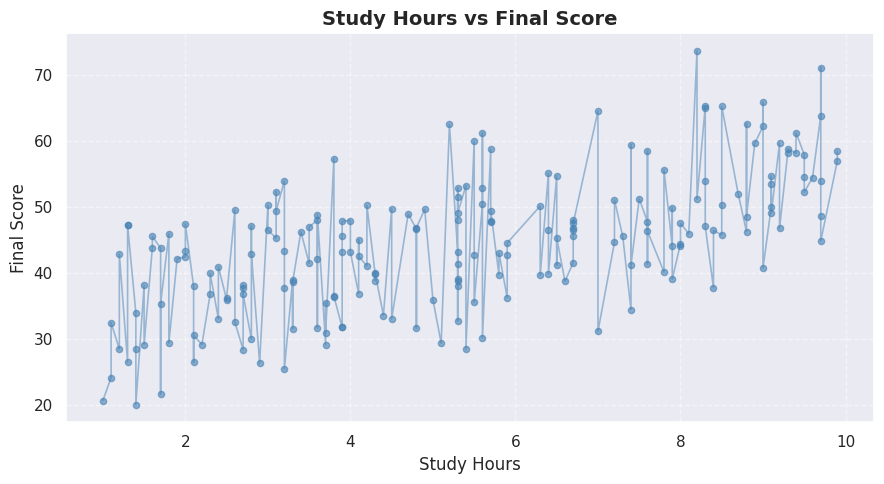

In [14]:
students_sorted = df.sort_values("study_hours")

plt.figure(figsize=(9, 5))
plt.plot(students_sorted["study_hours"], students_sorted["final_score"],
         color="steelblue", alpha=0.5, linewidth=1.2)
plt.scatter(students_sorted["study_hours"], students_sorted["final_score"],
            color="steelblue", s=20, alpha=0.6)
plt.xlabel("Study Hours", fontsize=12)
plt.ylabel("Final Score", fontsize=12)
plt.title("Study Hours vs Final Score", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 3.2 Bar Chart

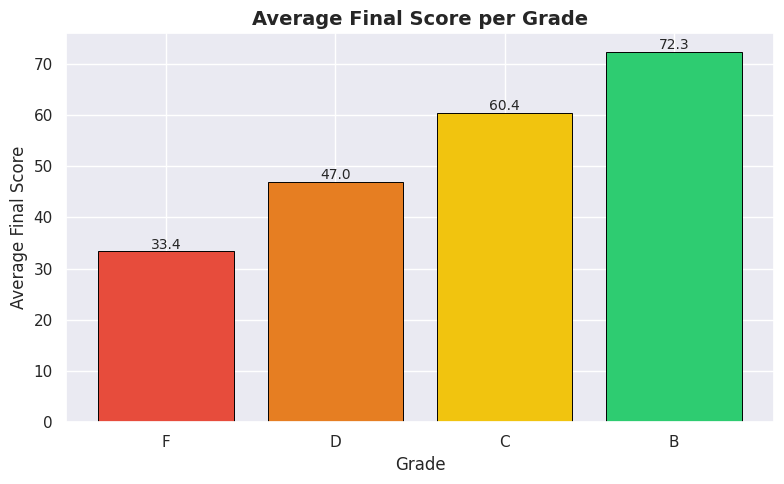

In [15]:
grade_avg = df.groupby("grade", observed=True)["final_score"].mean()

plt.figure(figsize=(8, 5))
bars = plt.bar(grade_avg.index, grade_avg.values,
               color=["#e74c3c","#e67e22","#f1c40f","#2ecc71","#3498db"],
               edgecolor="black", linewidth=0.7)

for bar, val in zip(bars, grade_avg.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f"{val:.1f}", ha="center", fontsize=10)

plt.xlabel("Grade", fontsize=12)
plt.ylabel("Average Final Score", fontsize=12)
plt.title("Average Final Score per Grade", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 3.3 Histogram

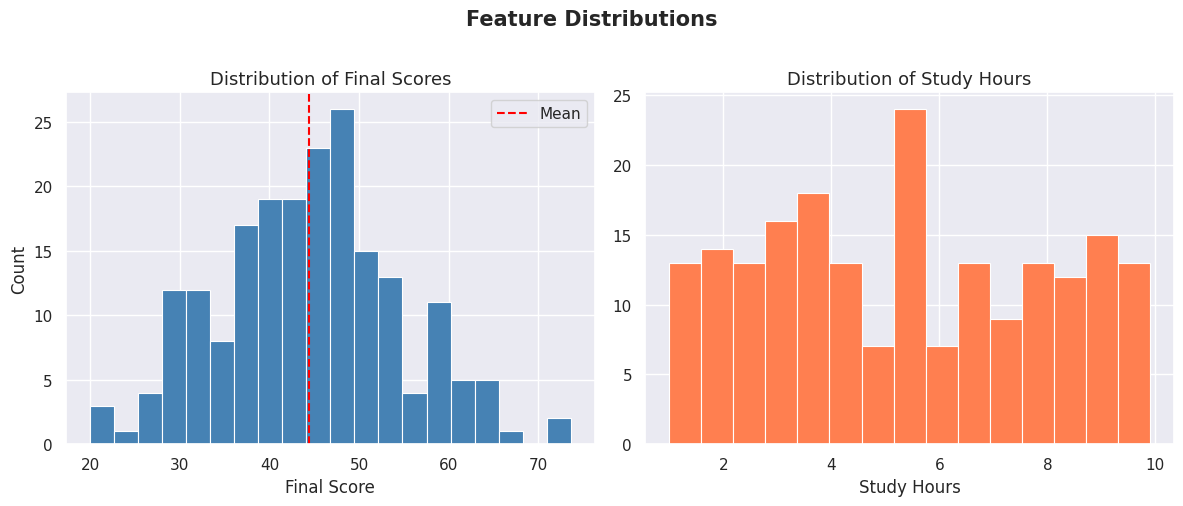

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(df["final_score"], bins=20, color="steelblue", edgecolor="white", linewidth=0.8)
axes[0].set_title("Distribution of Final Scores", fontsize=13)
axes[0].set_xlabel("Final Score")
axes[0].set_ylabel("Count")
axes[0].axvline(df["final_score"].mean(), color="red", linestyle="--", label="Mean")
axes[0].legend()

axes[1].hist(df["study_hours"], bins=15, color="coral", edgecolor="white", linewidth=0.8)
axes[1].set_title("Distribution of Study Hours", fontsize=13)
axes[1].set_xlabel("Study Hours")

plt.suptitle("Feature Distributions", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

### 3.4 Scatter Plot with Color Encoding

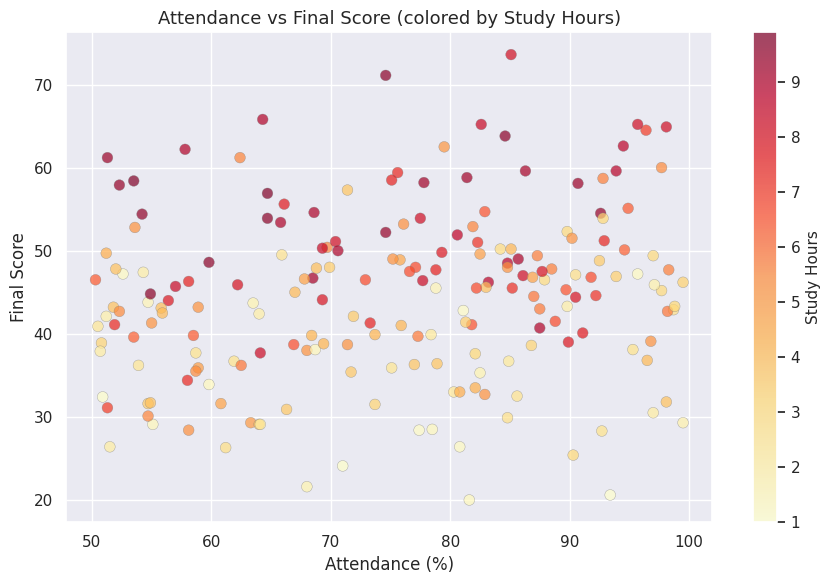

In [17]:
plt.figure(figsize=(9, 6))
scatter = plt.scatter(df["attendance"], df["final_score"],
                      c=df["study_hours"], cmap="YlOrRd",
                      alpha=0.7, s=60, edgecolors="gray", linewidth=0.3)

cbar = plt.colorbar(scatter)
cbar.set_label("Study Hours", fontsize=11)
plt.xlabel("Attendance (%)", fontsize=12)
plt.ylabel("Final Score", fontsize=12)
plt.title("Attendance vs Final Score (colored by Study Hours)", fontsize=13)
plt.tight_layout()
plt.show()

---
## 4. 🌊 Seaborn — Statistical Data Visualization

Seaborn builds on Matplotlib to produce beautiful statistical plots with less code. It integrates directly with Pandas DataFrames.


### 4.1 Distribution Plot

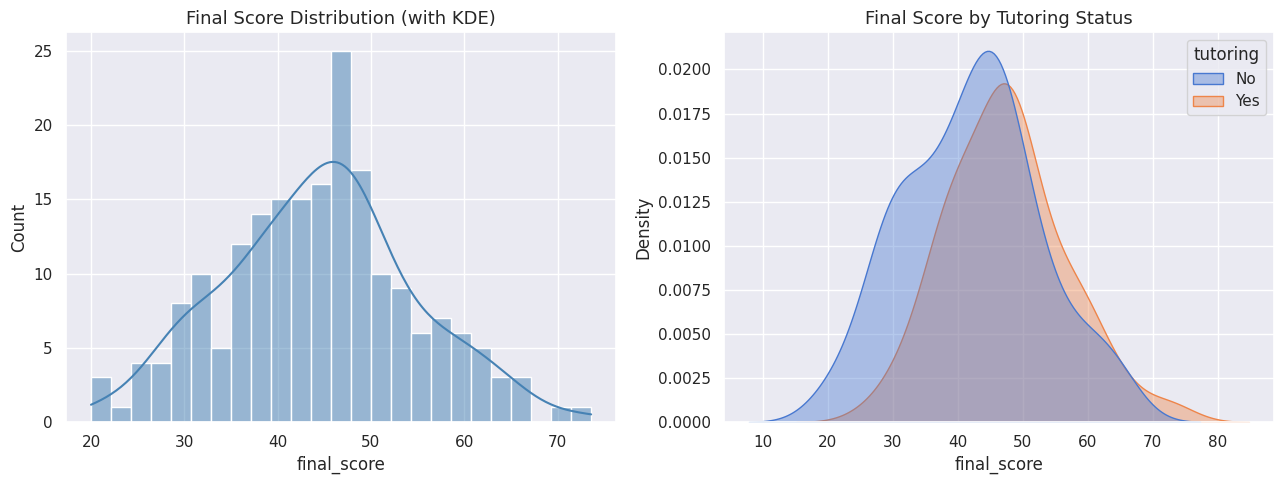

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["final_score"], kde=True, ax=axes[0], color="steelblue", bins=25)
axes[0].set_title("Final Score Distribution (with KDE)", fontsize=13)

sns.kdeplot(data=df, x="final_score", hue="tutoring", fill=True, alpha=0.4, ax=axes[1])
axes[1].set_title("Final Score by Tutoring Status", fontsize=13)

plt.tight_layout()
plt.show()

### 4.2 Box Plot — Spotting Outliers

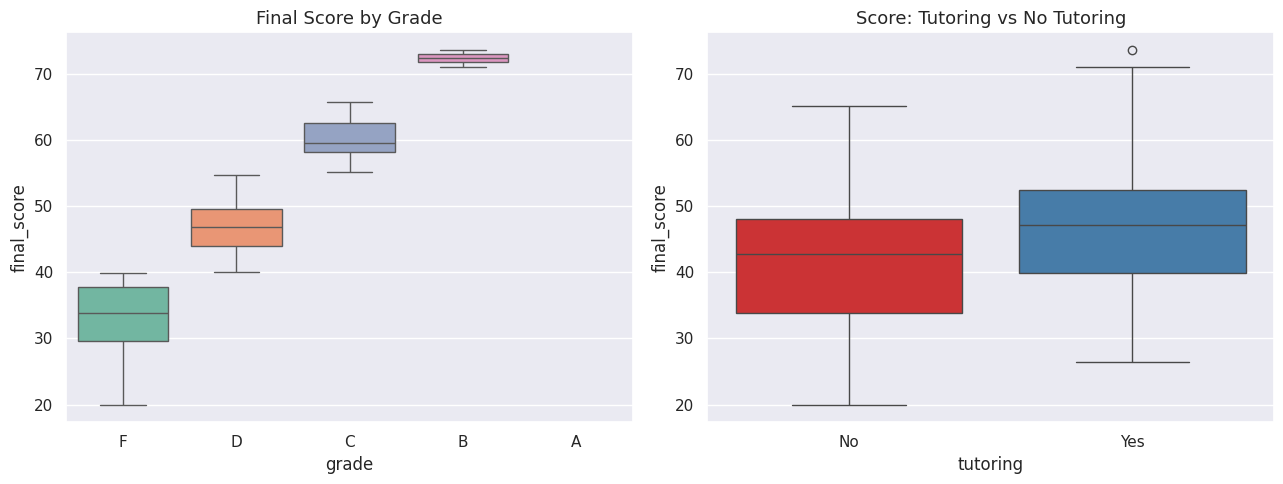

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x="grade", y="final_score", palette="Set2",
            order=["F","D","C","B","A"], ax=axes[0])
axes[0].set_title("Final Score by Grade", fontsize=13)

sns.boxplot(data=df, x="tutoring", y="final_score", palette="Set1", ax=axes[1])
axes[1].set_title("Score: Tutoring vs No Tutoring", fontsize=13)

plt.tight_layout()
plt.show()

### 4.3 Correlation Heatmap — Feature Relationships

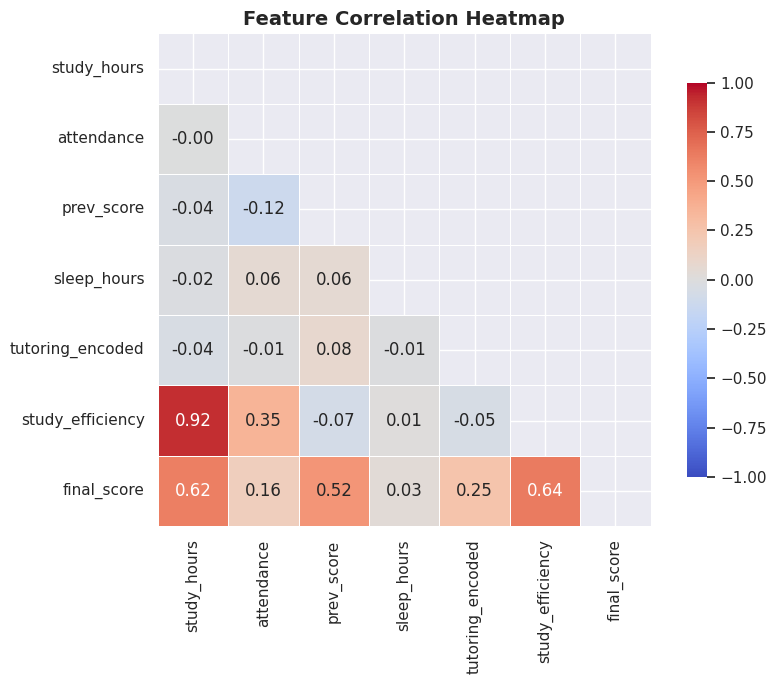

In [20]:
numeric_cols = ["study_hours","attendance","prev_score","sleep_hours",
                "tutoring_encoded","study_efficiency","final_score"]
corr = df[numeric_cols].corr()

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            mask=mask, vmin=-1, vmax=1,
            linewidths=0.5, square=True, cbar_kws={"shrink": 0.8})
plt.title("Feature Correlation Heatmap", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 4.4 Pairplot — Multi-Feature Overview

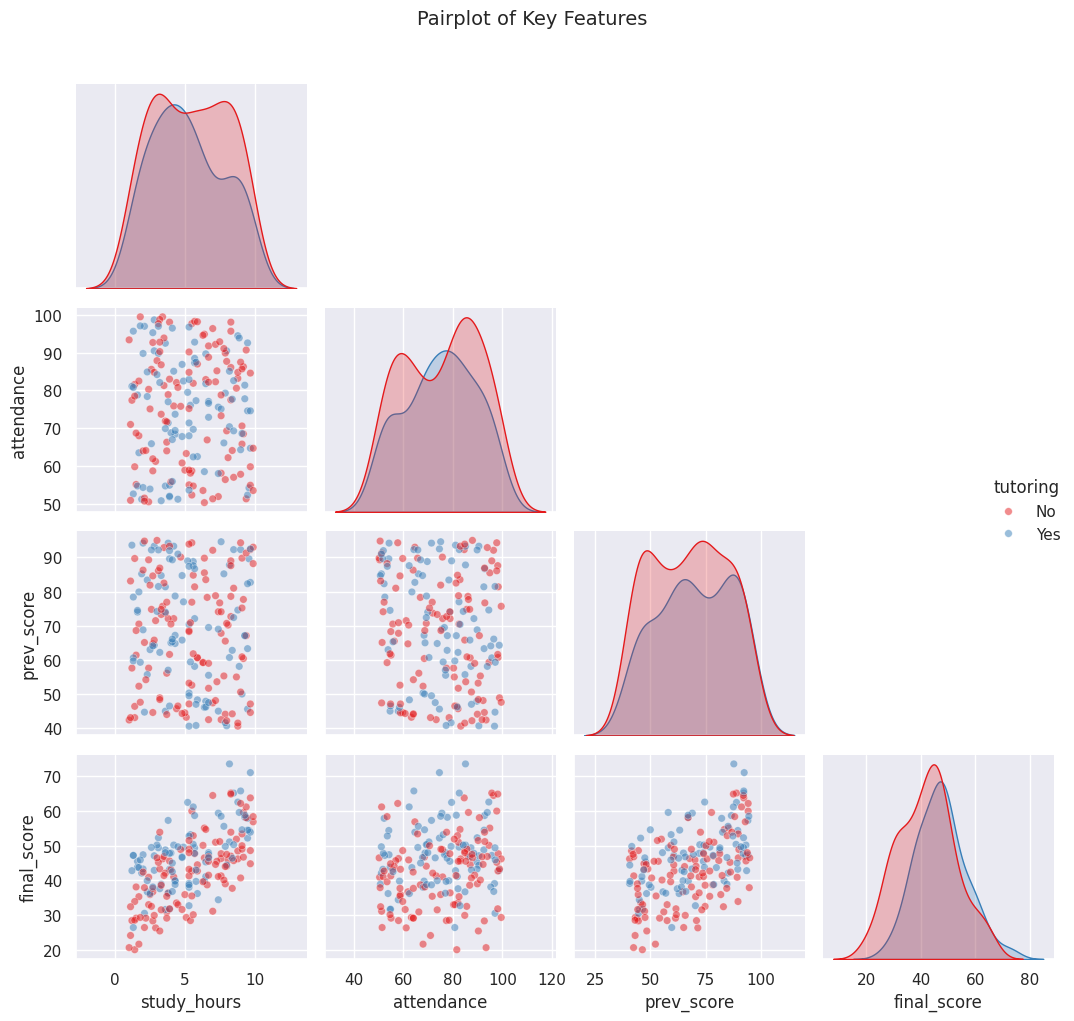

In [21]:
# Select key columns to avoid clutter
pair_cols = ["study_hours", "attendance", "prev_score", "final_score", "tutoring"]
sns.pairplot(df[pair_cols], hue="tutoring", palette="Set1",
             plot_kws={"alpha": 0.5, "s": 30},
             diag_kind="kde", corner=True)
plt.suptitle("Pairplot of Key Features", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

### 4.5 Bar Plot with Confidence Intervals

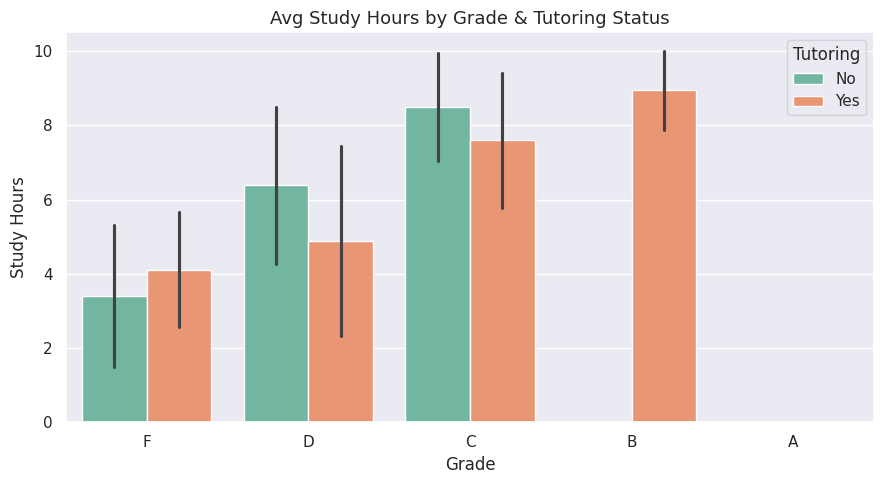

In [22]:
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="grade", y="study_hours", hue="tutoring",
            order=["F","D","C","B","A"], palette="Set2", errorbar="sd")
plt.title("Avg Study Hours by Grade & Tutoring Status", fontsize=13)
plt.xlabel("Grade")
plt.ylabel("Study Hours")
plt.legend(title="Tutoring")
plt.tight_layout()
plt.show()

### 4.6 Violin Plot

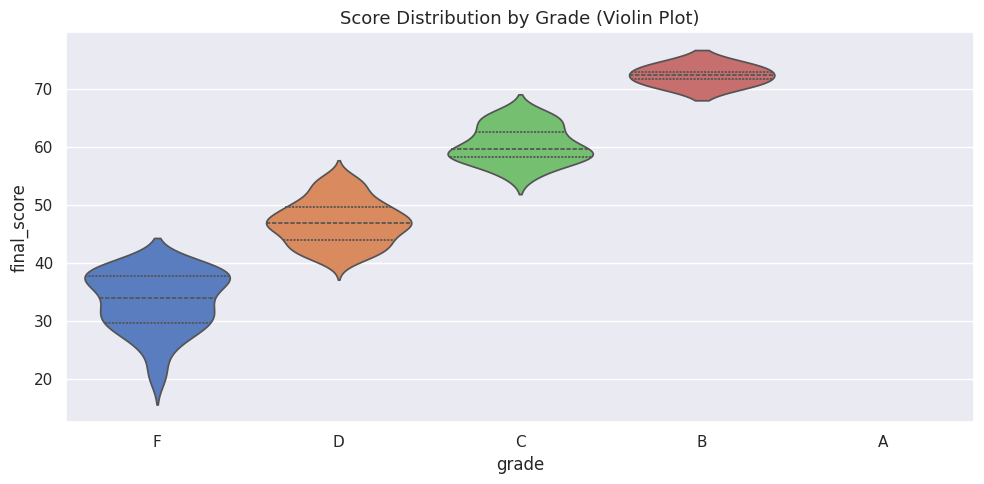

In [24]:
plt.figure(figsize=(10, 5))
sns.violinplot(data=df, x="grade", y="final_score", palette="muted",
               order=["F","D","C","B","A"], inner="quartile")
plt.title("Score Distribution by Grade (Violin Plot)", fontsize=13)
plt.tight_layout()
plt.show()

---
## 5. 🔗 Putting It All Together — Full ML EDA Workflow

This section shows how a real ML project starts: loading data → cleaning → exploring → visualizing.


In [ ]:
# Step 1: Load & inspect
df_eda = pd.read_csv("student_performance.csv")
print("Shape:", df_eda.shape)
print("\nMissing:")
print(df_eda.isnull().sum())

In [ ]:
# Step 2: Clean
df_eda["study_hours"].fillna(df_eda["study_hours"].median(), inplace=True)
df_eda["sleep_hours"].fillna(df_eda["sleep_hours"].median(), inplace=True)

# Step 3: Feature engineering
df_eda["tutoring_encoded"] = (df_eda["tutoring"] == "Yes").astype(int)
df_eda["grade"] = pd.cut(df_eda["final_score"],
                          bins=[0,40,55,70,85,100],
                          labels=["F","D","C","B","A"])

print("✅ Data cleaned and features engineered")
df_eda.head()

In [ ]:
# Step 4: Statistical summary per group
print(df_eda.groupby("tutoring")[["study_hours","attendance","final_score"]].mean().round(2))

In [ ]:
# Step 5: Full EDA Dashboard
fig = plt.figure(figsize=(16, 12))
fig.suptitle("Student Performance — EDA Dashboard", fontsize=16, fontweight="bold", y=1.01)

# Score distribution
ax1 = fig.add_subplot(2, 3, 1)
sns.histplot(df_eda["final_score"], kde=True, ax=ax1, color="steelblue", bins=20)
ax1.set_title("Score Distribution")

# Study hours vs score
ax2 = fig.add_subplot(2, 3, 2)
ax2.scatter(df_eda["study_hours"], df_eda["final_score"], alpha=0.5, color="coral", s=30)
ax2.set_xlabel("Study Hours")
ax2.set_ylabel("Final Score")
ax2.set_title("Study Hours vs Score")

# Attendance vs score
ax3 = fig.add_subplot(2, 3, 3)
ax3.scatter(df_eda["attendance"], df_eda["final_score"], alpha=0.5, color="seagreen", s=30)
ax3.set_xlabel("Attendance (%)")
ax3.set_ylabel("Final Score")
ax3.set_title("Attendance vs Score")

# Grade distribution
ax4 = fig.add_subplot(2, 3, 4)
grade_counts = df_eda["grade"].value_counts().sort_index()
ax4.bar(grade_counts.index, grade_counts.values,
        color=["#e74c3c","#e67e22","#f1c40f","#2ecc71","#3498db"])
ax4.set_title("Grade Distribution")

# Box: score by tutoring
ax5 = fig.add_subplot(2, 3, 5)
sns.boxplot(data=df_eda, x="tutoring", y="final_score", palette="Set1", ax=ax5)
ax5.set_title("Score by Tutoring")

# Correlation heatmap
ax6 = fig.add_subplot(2, 3, 6)
num_cols = ["study_hours","attendance","prev_score","sleep_hours","tutoring_encoded","final_score"]
corr = df_eda[num_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            ax=ax6, cbar=False, linewidths=0.5, square=True)
ax6.set_title("Correlation Heatmap")

plt.tight_layout()
plt.show()

print("\n✅ EDA Dashboard complete!")

---
## 6. 🧪 Practice Exercises

1. **NumPy:** From `final_score` column, convert it to a NumPy array. Compute mean, std, and manually normalize it between 0 and 1.
2. **Pandas:** Filter students with `attendance < 60` AND `final_score > 75`. How many such students exist? What does that tell you?
3. **Pandas:** Use `groupby` to find the average `sleep_hours` per `grade`. Which grade sleeps the most?
4. **Matplotlib:** Plot a bar chart of the count of students per `grade`. Add value labels on top of each bar.
5. **Seaborn:** Plot a heatmap showing the correlation of only `study_hours`, `prev_score`, and `final_score`. Which two features are most correlated?


In [ ]:
# Exercise 1: NumPy normalization
scores_array = df["final_score"].to_numpy()
# Your code here


In [ ]:
# Exercise 2: Filter low attendance + high score
result = df[(df["attendance"] < 60) & (df["final_score"] > 75)]
print(f"Count: {len(result)}")


In [ ]:
# Exercise 3: Sleep hours per grade
# Your code here


In [ ]:
# Exercise 4: Bar chart with labels
grade_counts = df["grade"].value_counts().sort_index()
# Your code here


In [ ]:
# Exercise 5: Small correlation heatmap
cols = ["study_hours", "prev_score", "final_score"]
# Your code here


---
## ✅ Summary

| Library | Purpose in ML |
|---|---|
| **NumPy** | Fast array math, vectorized ops, no-loop computation |
| **Pandas** | Load, clean, filter, engineer features from tabular data |
| **Matplotlib** | Full-control charts: line, bar, scatter, histogram |
| **Seaborn** | Statistical plots: heatmaps, violin, pairplot, KDE |

**Tomorrow (Day 6):** Concept Learning — Hypothesis space, Find-S, and Candidate Elimination.

For the full curriculum, visit **www.techvedhu.com**
